# F1 race prediction pipeline

This notebook builds a historical Formula 1 dataset from Jolpica-F1, creates the existing lagged predictors, trains regression models, and evaluates race-level finishing-order predictions.

**Important modelling choices**
- Historical standings recorded after race *n* are shifted to become features for race *n+1*.
- The target is the numeric classified finishing position returned by Jolpica. Drivers without a numeric classified position are excluded from regression training.
- Training and validation are split by whole races and in chronological order to better represent predicting future races.
- API responses and completed season CSVs are cached locally so rerunning the notebook does not repeatedly download the same data.


In [59]:
# Import packages
import hashlib
import json
import time
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Reduce FastF1 log messages
fastf1.set_log_level("ERROR")

# Jolpica API and local cache locations
BASE_URL = "https://api.jolpi.ca/ergast/f1"
CACHE_DIR = Path("f1_api_cache")
SEASON_DIR = Path("f1_historical_data_v3")

CACHE_DIR.mkdir(exist_ok=True)
SEASON_DIR.mkdir(exist_ok=True)

http = requests.Session()


## 1. Retrieve and cache Jolpica API data

In [60]:
def get_api_data(endpoint, params=None, refresh=False):
    """Retrieve one Jolpica endpoint, using a local cache when available."""

    url = f"{BASE_URL}/{endpoint}.json"

    # Make a stable cache filename for this endpoint and its parameters
    cache_key = json.dumps([endpoint, params], sort_keys=True)
    cache_name = hashlib.md5(cache_key.encode()).hexdigest()
    cache_file = CACHE_DIR / f"{cache_name}.json"

    # Use the saved response instead of making another API request
    if cache_file.exists() and not refresh:
        with open(cache_file, "r") as file:
            return json.load(file)

    # Retry rate limits and temporary server errors
    for attempt in range(6):
        response = http.get(url, params=params, timeout=30)

        if response.status_code == 429:
            retry_after = response.headers.get("Retry-After")
            try:
                wait_time = int(retry_after) if retry_after else 60 * (attempt + 1)
            except ValueError:
                wait_time = 60 * (attempt + 1)

            print(f"Rate limited. Waiting {wait_time} seconds...")
            time.sleep(wait_time)
            continue

        if response.status_code >= 500:
            wait_time = 30 * (attempt + 1)
            print(f"Server error. Retrying in {wait_time} seconds...")
            time.sleep(wait_time)
            continue

        response.raise_for_status()
        data = response.json()["MRData"]

        # Save successful responses for future runs
        with open(cache_file, "w") as file:
            json.dump(data, file)

        # Keep a small pause between uncached requests
        time.sleep(1.5)
        return data

    raise RuntimeError(f"Could not retrieve {endpoint} after 6 attempts.")


## 2. Retrieve race results and championship standings

In [61]:
def get_season_results(year, refresh=False):
    """Retrieve all race results for a season using API pagination."""

    limit = 100
    offset = 0

    # Store race information and results from every API page
    races_by_round = {}

    while True:

        # Retrieve the next page of results
        data = get_api_data(
            f"{year}/results",
            params={
                "limit": limit,
                "offset": offset
            }
        )

        races = data["RaceTable"]["Races"]
        total = int(data["total"])

        # Add the results from this page to the relevant race
        for race in races:

            round_number = int(race["round"])

            if round_number not in races_by_round:

                # Store the race information without its results
                races_by_round[round_number] = {
                    key: value
                    for key, value in race.items()
                    if key != "Results"
                }

                races_by_round[round_number]["Results"] = []

            # Append this page's driver results to the race
            races_by_round[round_number]["Results"].extend(
                race.get("Results", [])
            )

        print(
            f"{year}: Retrieved {min(offset + limit, total)} "
            f"of {total} result records"
        )

        # Move to the next page
        offset += limit

        # Stop when all records have been retrieved
        if offset >= total or not races:
            break

    # Convert the collected race results into a DataFrame
    season_results = []

    for round_number in sorted(races_by_round):

        race = races_by_round[round_number]

        for result in race["Results"]:

            season_results.append({

                "raceId": int(f"{year}{round_number}"),
                "year": int(year),
                "round": round_number,
                "date": race["date"],

                "driverId": result["Driver"]["driverId"],
                "constructorId": result["Constructor"]["constructorId"],

                "grid": result.get("grid"),
                "positionOrder": result.get("position")

            })

    return pd.DataFrame(season_results)


def get_race_standings(year, round_number, refresh=False):
    """Get driver and constructor standings after a specified race."""

    # Driver standings after this race
    driver_data = get_api_data(
        f"{year}/{round_number}/driverStandings", refresh=refresh
    )

    driver_standings = {}
    driver_lists = driver_data["StandingsTable"]["StandingsLists"]

    if driver_lists:
        for driver in driver_lists[0]["DriverStandings"]:
            driver_id = driver["Driver"]["driverId"]

            driver_standings[driver_id] = {
                "driver_points_per_round":
                    float(driver["points"]) / round_number,
                "driver_wins_per_round":
                    int(driver["wins"]) / round_number
            }

    # Constructor standings after this race
    constructor_data = get_api_data(
        f"{year}/{round_number}/constructorStandings", refresh=refresh
    )

    constructor_standings = {}
    constructor_lists = constructor_data["StandingsTable"]["StandingsLists"]

    if constructor_lists:
        for constructor in constructor_lists[0]["ConstructorStandings"]:
            constructor_id = constructor["Constructor"]["constructorId"]

            constructor_standings[constructor_id] = {
                "constructor_points_per_round":
                    float(constructor["points"]) / round_number,
                "constructor_wins_per_round":
                    int(constructor["wins"]) / round_number
            }

    return driver_standings, constructor_standings


In [62]:
def build_historical_dataset(start_year, end_year):

    all_seasons = []

    current_year = pd.Timestamp.now().year

    for year in range(start_year, end_year + 1):

        season_file = SEASON_DIR / f"{year}.csv"

        # Refresh the current season, but reuse completed seasons
        refresh = (year == current_year)

        if season_file.exists() and not refresh:

            print(f"Loading {year} from saved CSV...")

            season_results = pd.read_csv(season_file)
            all_seasons.append(season_results)

            continue

        print(f"Processing {year}...")

        season_results = get_season_results(
            year,
            refresh=refresh
        )

        if season_results.empty:
            continue

        # Create the standings columns
        standings_columns = [
            "driver_points_per_round",
            "driver_wins_per_round",
            "constructor_points_per_round",
            "constructor_wins_per_round"
        ]

        for column in standings_columns:
            season_results[column] = np.nan

        # Retrieve standings after each completed race
        for round_number in sorted(season_results["round"].unique()):

            driver_standings, constructor_standings = (
                get_race_standings(year, int(round_number), refresh=refresh)
            )

            race_mask = season_results["round"] == round_number

            for column in [
                "driver_points_per_round",
                "driver_wins_per_round"
            ]:

                season_results.loc[race_mask, column] = (
                    season_results.loc[race_mask, "driverId"]
                    .map({
                        key: value[column]
                        for key, value in driver_standings.items()
                    })
                )

            for column in [
                "constructor_points_per_round",
                "constructor_wins_per_round"
            ]:

                season_results.loc[race_mask, column] = (
                    season_results.loc[race_mask, "constructorId"]
                    .map({
                        key: value[column]
                        for key, value in constructor_standings.items()
                    })
                )

        # Save the updated season
        season_results.to_csv(season_file, index=False)

        all_seasons.append(season_results)

        print(f"Saved {year}.")

    return pd.concat(all_seasons, ignore_index=True)

## 3. Build the historical dataset

The example below retrieves 2010 through the current year. If a season CSV already exists in `f1_historical_data_v2`, it is reused.

If you change the data-collection logic, use a new season folder or delete the old season CSVs so that outdated files are not reused.


In [63]:
# Retrieve historical race results and standings
start_year = 2010
end_year = pd.Timestamp.now().year

combined_results = build_historical_dataset(start_year, end_year)

# Save one combined copy as well
combined_results.to_csv("historical_f1_results.csv", index=False)

print("Dataset shape:", combined_results.shape)
display(combined_results.head())


Loading 2010 from saved CSV...
Loading 2011 from saved CSV...
Loading 2012 from saved CSV...
Loading 2013 from saved CSV...
Loading 2014 from saved CSV...
Loading 2015 from saved CSV...
Loading 2016 from saved CSV...
Loading 2017 from saved CSV...
Loading 2018 from saved CSV...
Loading 2019 from saved CSV...
Loading 2020 from saved CSV...
Loading 2021 from saved CSV...
Loading 2022 from saved CSV...
Loading 2023 from saved CSV...
Loading 2024 from saved CSV...
Loading 2025 from saved CSV...
Processing 2026...
2026: Retrieved 100 of 462 result records
2026: Retrieved 200 of 462 result records
2026: Retrieved 300 of 462 result records
2026: Retrieved 400 of 462 result records
2026: Retrieved 462 of 462 result records
Saved 2026.
Dataset shape: (7373, 12)


,raceId,year,round,date,driverId,constructorId,grid,positionOrder,driver_points_per_round,driver_wins_per_round,constructor_points_per_round,constructor_wins_per_round
0,20101,2010,1,2010-03-14,alonso,ferrari,3,1,25.0,1.0,43.0,1.0
1,20101,2010,1,2010-03-14,massa,ferrari,2,2,18.0,0.0,43.0,1.0
2,20101,2010,1,2010-03-14,hamilton,mclaren,4,3,15.0,0.0,21.0,0.0
3,20101,2010,1,2010-03-14,vettel,red_bull,1,4,12.0,0.0,16.0,0.0
4,20101,2010,1,2010-03-14,rosberg,mercedes,5,5,10.0,0.0,18.0,0.0


## 4. Clean the data and create lagged predictors

In [64]:
# Convert the modelling columns to numeric values
numeric_columns = [
    "grid",
    "positionOrder",
    "driver_points_per_round",
    "driver_wins_per_round",
    "constructor_points_per_round",
    "constructor_wins_per_round"
]

combined_results[numeric_columns] = (
    combined_results[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# Convert dates and remove rows without a usable target
combined_results["date"] = pd.to_datetime(
    combined_results["date"], errors="coerce"
)

combined_results = combined_results.dropna(
    subset=["date", "positionOrder"]
).copy()

# Sort each driver's races chronologically before creating lags
combined_results = combined_results.sort_values(
    ["driverId", "date", "year", "round"]
).reset_index(drop=True)

# These are the six existing predictor variables
lag_columns = [
    "grid",
    "positionOrder",
    "driver_points_per_round",
    "driver_wins_per_round",
    "constructor_points_per_round",
    "constructor_wins_per_round"
]

lagged_results = combined_results.copy()

# Shift each variable by one race for each driver
for column in lag_columns:
    lagged_results[f"{column}_lag1"] = (
        lagged_results.groupby("driverId")[column].shift(1)
    )

# Remove rows where any previous-race predictor is unavailable
lagged_features = [f"{column}_lag1" for column in lag_columns]

lagged_results = lagged_results.dropna(
    subset=lagged_features
).reset_index(drop=True)

# Keep raceId numeric so it sorts numerically
lagged_results["raceId"] = pd.to_numeric(
    lagged_results["raceId"], errors="coerce"
).astype("Int64")

# Define the predictors and target
features = [
    "grid_lag1",
    "positionOrder_lag1",
    "driver_points_per_round_lag1",
    "driver_wins_per_round_lag1"
    #"constructor_points_per_round_lag1",
    #"constructor_wins_per_round_lag1"
]

X = lagged_results[features].astype(float)
y = lagged_results["positionOrder"].astype(float)
groups = lagged_results["raceId"]

print("Rows available for modelling:", len(lagged_results))
print("Missing predictor values:")
print(X.isna().sum())

display(
    lagged_results.sort_values(["year", "round", "positionOrder"]).head(10)
)


Rows available for modelling: 7287
Missing predictor values:
grid_lag1                       0
positionOrder_lag1              0
driver_points_per_round_lag1    0
driver_wins_per_round_lag1      0
dtype: int64


,raceId,year,round,date,driverId,constructorId,grid,positionOrder,driver_points_per_round,driver_wins_per_round,constructor_points_per_round,constructor_wins_per_round,grid_lag1,positionOrder_lag1,driver_points_per_round_lag1,driver_wins_per_round_lag1,constructor_points_per_round_lag1,constructor_wins_per_round_lag1
1078,20102,2010,2,2010-03-28,button,mclaren,4,1,15.5,0.5,27.0,0.5,8.0,7.0,6.0,0.0,21.0,0.0
3103,20102,2010,2,2010-03-28,kubica,renault,9,2,9.0,0.0,9.0,0.0,9.0,11.0,0.0,0.0,0.0,0.0
3693,20102,2010,2,2010-03-28,massa,ferrari,5,3,16.5,0.0,35.0,0.5,2.0,2.0,18.0,0.0,43.0,1.0
186,20102,2010,2,2010-03-28,alonso,ferrari,3,4,18.5,0.5,35.0,0.5,3.0,1.0,25.0,1.0,43.0,1.0
5672,20102,2010,2,2010-03-28,rosberg,mercedes,6,5,10.0,0.0,14.5,0.0,5.0,5.0,10.0,0.0,18.0,0.0
2041,20102,2010,2,2010-03-28,hamilton,mclaren,11,6,11.5,0.0,27.0,0.5,4.0,3.0,15.0,0.0,21.0,0.0
3563,20102,2010,2,2010-03-28,liuzzi,force_india,13,7,4.0,0.0,4.0,0.0,12.0,9.0,2.0,0.0,2.0,0.0
577,20102,2010,2,2010-03-28,barrichello,williams,8,8,2.5,0.0,2.5,0.0,11.0,10.0,1.0,0.0,1.0,0.0
7100,20102,2010,2,2010-03-28,webber,red_bull,2,9,3.0,0.0,9.0,0.0,6.0,8.0,4.0,0.0,16.0,0.0
4133,20102,2010,2,2010-03-28,michael_schumacher,mercedes,7,10,4.5,0.0,14.5,0.0,7.0,6.0,8.0,0.0,18.0,0.0


## 5. Create chronological, race-level training and test sets

The final 10% of races are held out for testing. All drivers from a race stay together, and the test set contains later races than the training set.

This is more representative of using the model to predict upcoming races than randomly selecting races from across the entire historical period.


In [65]:
# Get the unique races in chronological order
race_calendar = (
    lagged_results[["raceId", "date", "year", "round"]]
    .drop_duplicates()
    .sort_values(["date", "year", "round"])
    .reset_index(drop=True)
)

# Reserve the latest 10% of races for the final test set
test_race_count = max(1, int(np.ceil(len(race_calendar) * 0.10)))
test_race_ids = race_calendar.tail(test_race_count)["raceId"]

train_data = (
    lagged_results[~lagged_results["raceId"].isin(test_race_ids)]
    .sort_values(["date", "year", "round", "driverId"])
    .reset_index(drop=True)
)

test_data = (
    lagged_results[lagged_results["raceId"].isin(test_race_ids)]
    .sort_values(["date", "year", "round", "driverId"])
    .reset_index(drop=True)
)

X_train = train_data[features]
X_test = test_data[features]
y_train = train_data["positionOrder"]
y_test = test_data["positionOrder"]

print("Training races:", train_data["raceId"].nunique())
print("Testing races:", test_data["raceId"].nunique())
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))


Training races: 314
Testing races: 35
Training rows: 6548
Testing rows: 739


## 6. Create chronological cross-validation folds

Each fold trains on earlier races and validates on later races. This avoids placing drivers from the same race in different folds and avoids training on races that occur after a validation race.


In [66]:
# Build cross-validation splits using race IDs, not individual driver rows
train_races = (
    train_data[["raceId", "date", "year", "round"]]
    .drop_duplicates()
    .sort_values(["date", "year", "round"])
    .reset_index(drop=True)
)

if len(train_races) < 6:
    raise ValueError("Not enough training races for five chronological CV folds.")

time_splitter = TimeSeriesSplit(n_splits=5)
cv_splits = []

for earlier_race_idx, later_race_idx in time_splitter.split(train_races):
    earlier_race_ids = train_races.iloc[earlier_race_idx]["raceId"]
    later_race_ids = train_races.iloc[later_race_idx]["raceId"]

    # Convert race groups into row positions within train_data
    fold_train_idx = np.flatnonzero(
        train_data["raceId"].isin(earlier_race_ids).to_numpy()
    )
    fold_valid_idx = np.flatnonzero(
        train_data["raceId"].isin(later_race_ids).to_numpy()
    )

    cv_splits.append((fold_train_idx, fold_valid_idx))

print("Number of CV folds:", len(cv_splits))


Number of CV folds: 5


## 7. Explore predictor relationships

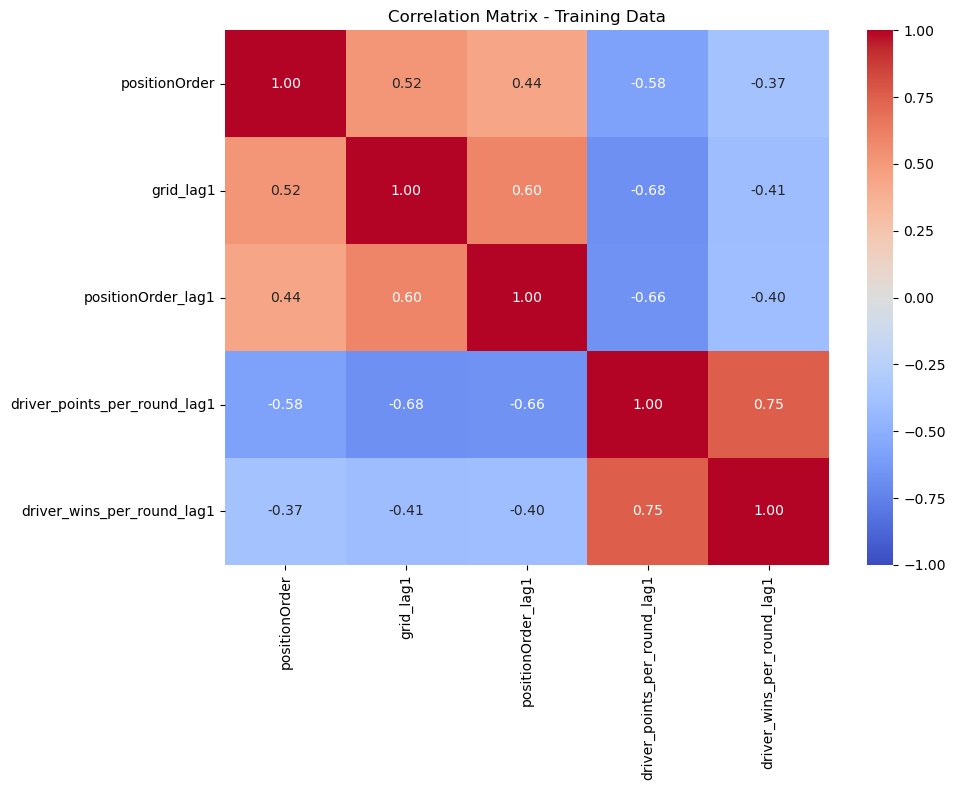

driver_points_per_round_lag1   -0.578747
grid_lag1                       0.522870
positionOrder_lag1              0.444876
driver_wins_per_round_lag1     -0.369975
Name: positionOrder, dtype: float64

,Variable,VIF
1,positionOrder_lag1,5.514136
0,grid_lag1,5.448244
2,driver_points_per_round_lag1,2.683192
3,driver_wins_per_round_lag1,2.438311


In [67]:
# Calculate correlations using training data only
data_train = pd.concat([y_train.rename("positionOrder"), X_train], axis=1)
correlation_matrix = data_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation Matrix - Training Data")
plt.tight_layout()
plt.show()

# Show correlations with the target, ordered by absolute size
target_correlations = correlation_matrix["positionOrder"].drop("positionOrder")
target_correlations = target_correlations.reindex(
    target_correlations.abs().sort_values(ascending=False).index
)

display(target_correlations)

# Calculate VIF for the training predictors
vif = pd.DataFrame({
    "Variable": X_train.columns,
    "VIF": [
        variance_inflation_factor(X_train.to_numpy(), i)
        for i in range(X_train.shape[1])
    ]
})

display(vif.sort_values("VIF", ascending=False))


## 8. Ridge regression

In [68]:
# Standardise predictors before fitting Ridge regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Evaluate on the chronological race-level folds
ridge_mae_scores = []

for train_idx, valid_idx in cv_splits:
    # Fit on earlier races and evaluate on the next validation block
    ridge_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    predictions = ridge_model.predict(X_train.iloc[valid_idx])

    ridge_mae_scores.append(
        mean_absolute_error(y_train.iloc[valid_idx], predictions)
    )

print("Ridge CV MAE scores:", ridge_mae_scores)
print("Mean CV MAE:", np.mean(ridge_mae_scores))
print("SD of CV MAE:", np.std(ridge_mae_scores, ddof=1))


Ridge CV MAE scores: [3.8635475670704476, 3.8208966734550525, 3.8301693966777965, 3.7696530562190964, 3.4145295554827038]
Mean CV MAE: 3.7397592497810193
SD of CV MAE: 0.18489782137469707


## 9. Partial least squares regression

In [69]:
# Standardise predictors before fitting PLS regression
pls_model = make_pipeline(
    StandardScaler(),
    PLSRegression(n_components=3)
)

pls_mae_scores = []

for train_idx, valid_idx in cv_splits:
    # Fit on earlier races and predict the next validation block
    pls_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    predictions = pls_model.predict(
        X_train.iloc[valid_idx]
    ).ravel()

    pls_mae_scores.append(
        mean_absolute_error(y_train.iloc[valid_idx], predictions)
    )

print("PLS CV MAE scores:", pls_mae_scores)
print("Mean CV MAE:", np.mean(pls_mae_scores))
print("SD of CV MAE:", np.std(pls_mae_scores, ddof=1))


PLS CV MAE scores: [3.872156565027618, 3.816343605605859, 3.862419443412266, 3.8196359572171183, 3.4466955816568525]
Mean CV MAE: 3.763450230583943
SD of CV MAE: 0.1788155647947553


## 10. Gradient Boosting regression

In [70]:
# Define the Gradient Boosting model and parameter combinations
gb_param_grid = {
    "n_estimators": [150, 250],
    "learning_rate": [0.03, 0.05],
    "max_depth": [2, 3],
    "min_samples_split": [4],
    "min_samples_leaf": [3, 5]
}

gb_model = GradientBoostingRegressor(
    loss="squared_error",
    random_state=42
)

# Search using the chronological race-level folds
grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=gb_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

grid_search_gb.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(grid_search_gb.best_params_)

best_model_gb = grid_search_gb.best_estimator_

# Display the best parameter combinations
gb_cv_results = pd.DataFrame(grid_search_gb.cv_results_)

gb_cv_results["Mean CV MAE"] = -gb_cv_results["mean_test_score"]
gb_cv_results["SD of CV MAE"] = gb_cv_results["std_test_score"]

gb_cv_results = gb_cv_results.sort_values("Mean CV MAE")

display(gb_cv_results[[
    "param_n_estimators",
    "param_learning_rate",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
    "Mean CV MAE",
    "SD of CV MAE"
]].head(10))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Gradient Boosting parameters:
{'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 5, 'min_samples_split': 4, 'n_estimators': 250}


,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_split,param_min_samples_leaf,Mean CV MAE,SD of CV MAE
3,250,0.03,2,4,5,3.749432,0.173640
8,150,0.05,2,4,3,3.749456,0.176176
1,250,0.03,2,4,3,3.749794,0.174351
10,150,0.05,2,4,5,3.749863,0.175243
6,150,0.03,3,4,5,3.755337,0.168829
4,150,0.03,3,4,3,3.757086,0.169206
7,250,0.03,3,4,5,3.757463,0.174731
0,150,0.03,2,4,3,3.757578,0.165166
14,150,0.05,3,4,5,3.758512,0.175598
2,150,0.03,2,4,5,3.759117,0.165622


## 11. Neural network regression

In [71]:
# Scale predictors because neural networks are sensitive to feature scales
nn_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=42,
        early_stopping=False
    )
)

# Test a small selection of network architectures and regularisation strengths
nn_param_grid = {
    "mlpregressor__hidden_layer_sizes": [
        (64,),
        (64, 32),
        (128, 64)
    ],
    "mlpregressor__activation": ["relu", "tanh"],
    "mlpregressor__alpha": [0.001, 0.01],
    "mlpregressor__learning_rate_init": [0.001]
}

grid_search_nn = GridSearchCV(
    estimator=nn_model,
    param_grid=nn_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

grid_search_nn.fit(X_train, y_train)

print("Best neural network parameters:")
print(grid_search_nn.best_params_)

best_model_nn = grid_search_nn.best_estimator_

# Display the best neural network configurations
nn_cv_results = pd.DataFrame(grid_search_nn.cv_results_)
nn_cv_results["Mean CV MAE"] = -nn_cv_results["mean_test_score"]
nn_cv_results["SD of CV MAE"] = nn_cv_results["std_test_score"]
nn_cv_results = nn_cv_results.sort_values("Mean CV MAE")

display(nn_cv_results[[
    "param_mlpregressor__hidden_layer_sizes",
    "param_mlpregressor__activation",
    "param_mlpregressor__alpha",
    "param_mlpregressor__learning_rate_init",
    "Mean CV MAE",
    "SD of CV MAE"
]].head(10))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best neural network parameters:
{'mlpregressor__activation': 'relu', 'mlpregressor__alpha': 0.01, 'mlpregressor__hidden_layer_sizes': (128, 64), 'mlpregressor__learning_rate_init': 0.001}


,param_mlpregressor__hidden_layer_sizes,param_mlpregressor__activation,param_mlpregressor__alpha,param_mlpregressor__learning_rate_init,Mean CV MAE,SD of CV MAE
5,"(128, 64)",relu,0.010,0.001,3.703814,0.161958
1,"(64, 32)",relu,0.001,0.001,3.713629,0.175189
3,"(64,)",relu,0.010,0.001,3.718668,0.166248
0,"(64,)",relu,0.001,0.001,3.718851,0.166339
2,"(128, 64)",relu,0.001,0.001,3.731754,0.179430
4,"(64, 32)",relu,0.010,0.001,3.732259,0.180981
9,"(64,)",tanh,0.010,0.001,3.732372,0.162593
6,"(64,)",tanh,0.001,0.001,3.732401,0.162602
7,"(64, 32)",tanh,0.001,0.001,3.752684,0.196039
10,"(64, 32)",tanh,0.010,0.001,3.752699,0.196280


## 12. Evaluate predictions by race

The model predicts a numeric finishing position for each driver. We then rank those predictions within each race, with the lowest predicted position assigned rank 1.

Because the test set contains complete held-out race groups (after removing rows without a usable target or lagged predictors), we can compare these within-race ranks with actual classified positions.


In [72]:
# Choose the trained model for final testing
final_model = best_model_nn

# Predict finishing positions for the held-out races
y_pred = np.asarray(final_model.predict(X_test)).ravel()

# Add predictions to the matching test rows
test_results = test_data.copy()
test_results["predicted_position"] = y_pred

# Rank predicted positions within each race
test_results["predicted_rank"] = (
    test_results.groupby("raceId")["predicted_position"]
    .rank(method="first", ascending=True)
    .astype(int)
)

# Sort by race and predicted finishing position
test_results = test_results.sort_values(
    ["year", "round", "predicted_rank"]
).reset_index(drop=True)

display(test_results[[
    "raceId",
    "year",
    "round",
    "driverId",
    "positionOrder",
    "predicted_position",
    "predicted_rank"
]].tail(30))

# Compare actual classified position with predicted within-race rank
y_actual = test_results["positionOrder"]
y_ranked = test_results["predicted_rank"]

absolute_errors = np.abs(y_actual - y_ranked)

print("Ranked Prediction Performance")
print(f"MAE: {mean_absolute_error(y_actual, y_ranked):.4f}")
print(f"SD:  {absolute_errors.std(ddof=1):.4f}")

# Also report error on the model's raw numerical predictions
print("\nRaw Position Prediction Performance")
print(f"MAE: {mean_absolute_error(y_actual, test_results['predicted_position']):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_actual, test_results['predicted_position'])):.4f}")
print(f"R²: {r2_score(y_actual, test_results['predicted_position']):.4f}")


,raceId,year,round,driverId,positionOrder,predicted_position,predicted_rank
709,202620,2026,20,bearman,17,12.655654,14
710,202620,2026,20,bortoleto,16,12.972644,15
711,202620,2026,20,sainz,19,13.464401,16
712,202620,2026,20,albon,15,13.594900,17
713,202620,2026,20,alonso,12,14.697527,18
714,202620,2026,20,stroll,21,16.036626,19
715,202620,2026,20,perez,18,16.275213,20
716,202620,2026,20,bottas,22,17.001472,21
717,202621,2026,21,antonelli,4,2.825701,1
718,202621,2026,21,hamilton,7,5.526522,2


Ranked Prediction Performance
MAE: 4.0054
SD:  3.7166

Raw Position Prediction Performance
MAE: 3.8051
RMSE: 4.8420
R²: 0.3810


## 13. Retrieve the current season calendar and session data

These helper cells are for the weekly prediction workflow. Select a race and session explicitly; do not assume the next race has already held qualifying or practice.


In [73]:
# Retrieve the current season calendar from FastF1
current_year = pd.Timestamp.now().year

schedule = fastf1.get_event_schedule(current_year)
schedule = schedule[schedule["RoundNumber"] > 0].copy()
schedule["EventDate"] = pd.to_datetime(schedule["EventDate"])

display(schedule[["RoundNumber", "EventName", "EventDate"]])


,RoundNumber,EventName,EventDate
2,1,Australian Grand Prix,2026-03-08
3,2,Chinese Grand Prix,2026-03-15
4,3,Japanese Grand Prix,2026-03-29
5,4,Miami Grand Prix,2026-05-03
6,5,Canadian Grand Prix,2026-05-24
7,6,Monaco Grand Prix,2026-06-07
8,7,Barcelona Grand Prix,2026-06-14
9,8,Austrian Grand Prix,2026-06-28
10,9,British Grand Prix,2026-07-05
11,10,Belgian Grand Prix,2026-07-19


In [76]:
# Get the current season's race calendar
current_year = pd.Timestamp.now().year

schedule = fastf1.get_event_schedule(current_year)

schedule = schedule[schedule['RoundNumber'] > 0].copy()

# Convert event dates to datetime
schedule['EventDate'] = pd.to_datetime(
    schedule['EventDate'],
    utc=True
)

# Find the next upcoming race
today = pd.Timestamp.now(tz='UTC')

upcoming_races = schedule[
    schedule['EventDate'] >= today
].sort_values('EventDate')

if upcoming_races.empty:
    raise ValueError('No upcoming races found in the current season.')

next_race = upcoming_races.iloc[0]

next_round = int(next_race['RoundNumber'])

print(f"Upcoming race: {next_race['EventName']}")
print(f"Round: {next_round}")
print(f"Date: {next_race['EventDate']}")

Upcoming race: Qatar Grand Prix
Round: 22
Date: 2026-11-29 00:00:00+00:00


In [77]:
# Retrieve the latest results for the current season
current_results = get_season_results(
    current_year,
    refresh=True
)

if current_results.empty:
    raise ValueError('No completed races found for the current season.')

# Identify the latest completed round
latest_round = int(current_results['round'].max())

# Get the results from that race
latest_race_results = current_results[
    current_results['round'] == latest_round
].copy()

print(f'Latest completed round: {latest_round}')

display(
    latest_race_results[
        ['driverId', 'constructorId', 'grid', 'positionOrder']
    ].head()
)

2026: Retrieved 100 of 462 result records
2026: Retrieved 200 of 462 result records
2026: Retrieved 300 of 462 result records
2026: Retrieved 400 of 462 result records
2026: Retrieved 462 of 462 result records
Latest completed round: 21


,driverId,constructorId,grid,positionOrder
440,max_verstappen,red_bull,1,1
441,norris,mclaren,3,2
442,piastri,mclaren,17,3
443,antonelli,mercedes,6,4
444,gasly,alpine,8,5


In [78]:
# Retrieve updated driver and constructor standings
driver_standings, constructor_standings = get_race_standings(
    current_year,
    latest_round,
    refresh=True
)

In [79]:
# Store the prediction features for each driver
upcoming_data = []

for index, row in latest_race_results.iterrows():

    driver_id = row['driverId']
    constructor_id = row['constructorId']

    # Retrieve the driver's latest championship statistics
    driver_features = driver_standings.get(driver_id)

    # Retrieve the constructor's latest championship statistics
    constructor_features = constructor_standings.get(constructor_id)

    # Skip drivers without sufficient historical information
    if driver_features is None or constructor_features is None:
        continue

    upcoming_data.append({

        'raceId': int(f'{current_year}{next_round}'),

        'driverId': driver_id,
        'constructorId': constructor_id,

        # Previous race performance
        'grid_lag1': row['grid'],
        'positionOrder_lag1': row['positionOrder'],

        # Latest driver championship statistics
        'driver_points_per_round_lag1':
            driver_features['driver_points_per_round'],

        'driver_wins_per_round_lag1':
            driver_features['driver_wins_per_round'],

        # Latest constructor championship statistics
        'constructor_points_per_round_lag1':
            constructor_features['constructor_points_per_round'],

        'constructor_wins_per_round_lag1':
            constructor_features['constructor_wins_per_round']

    })

# Convert the collected observations into a DataFrame
upcoming_data = pd.DataFrame(upcoming_data)

# Remove drivers with missing predictor values
upcoming_data = upcoming_data.dropna(
    subset=features
).reset_index(drop=True)

# Display the prediction features
display(upcoming_data.head(10))

print('Drivers available for prediction:', len(upcoming_data))

,raceId,driverId,constructorId,grid_lag1,positionOrder_lag1,driver_points_per_round_lag1,driver_wins_per_round_lag1,constructor_points_per_round_lag1,constructor_wins_per_round_lag1
0,202622,max_verstappen,red_bull,1,1,14.476190,0.190476,20.952381,0.190476
1,202622,norris,mclaren,3,2,12.571429,0.142857,20.523810,0.142857
2,202622,piastri,mclaren,17,3,7.952381,0.000000,20.523810,0.142857
3,202622,antonelli,mercedes,6,4,19.142857,0.428571,31.714286,0.571429
4,202622,gasly,alpine,8,5,2.476190,0.000000,4.142857,0.000000
5,202622,colapinto,alpine,9,6,1.666667,0.000000,4.142857,0.000000
6,202622,hamilton,ferrari,11,7,12.714286,0.047619,24.619048,0.095238
7,202622,sainz,williams,20,8,0.523810,0.000000,0.761905,0.000000
8,202622,russell,mercedes,2,9,12.571429,0.142857,31.714286,0.571429
9,202622,leclerc,ferrari,10,10,11.904762,0.047619,24.619048,0.095238


Drivers available for prediction: 22


In [80]:
# Select the six predictor columns in the original training order
X_upcoming = upcoming_data[features]

# Generate predicted finishing positions
y_pred = best_model_nn.predict(X_upcoming).ravel()

# Store predictions
upcoming_data['predicted_position'] = y_pred

# Rank drivers within the upcoming race
upcoming_data['predicted_rank'] = (
    upcoming_data['predicted_position']
    .rank(method='first', ascending=True)
    .astype(int)
)

# Sort by predicted finishing position
upcoming_data = upcoming_data.sort_values(
    'predicted_rank'
).reset_index(drop=True)

In [81]:
# Display the predicted finishing order
display(
    upcoming_data[[
        'predicted_rank',
        'driverId',
        'constructorId',
        'predicted_position'
    ]]
)

,predicted_rank,driverId,constructorId,predicted_position
0,1,antonelli,mercedes,3.445985
1,2,russell,mercedes,5.357376
2,3,max_verstappen,red_bull,6.204167
3,4,norris,mclaren,6.586041
4,5,piastri,mclaren,7.173920
5,6,hamilton,ferrari,7.535008
6,7,leclerc,ferrari,7.865145
7,8,hadjar,red_bull,8.129822
8,9,lawson,rb,9.903975
9,10,arvid_lindblad,rb,10.294560


## Notes for the weekly prediction workflow

1. Load the saved historical dataset and create the same lagged features.
2. Retrieve the latest driver and constructor standings **from before the race being predicted**.
3. Retrieve practice and qualifying information only if the prediction is being made after those sessions.
4. Map FastF1 driver abbreviations to Jolpica driver IDs before joining the data.
5. Use the same feature order and preprocessing as the trained model.

The notebook currently builds and evaluates the historical model. It does not yet automatically construct a complete upcoming-race feature table from live practice/qualifying data; that requires a separate mapping and feature-assembly step.
